# RNN分类器

实现一个RNN分类器，输入名字预测所属国家

In [8]:
import csv
import gzip
import time
from torch.utils.data import Dataset
import torch
from torch.utils.data import DataLoader
from torch.nn.utils.rnn import pack_padded_sequence
import matplotlib.pyplot as plt
import numpy as np

class NameDataset(Dataset):
    def __init__(self, is_train_set=True):
        filename = 'data/names_train.csv.gz' if is_train_set else 'data/names_test.csv.gz'
        # 判断是训练集还是测试集
        with gzip.open(filename, 'rt') as f:
            reader = csv.reader(f)
            rows = list(reader) # 每一行读取成一个元组（name，country）

        self.names = [row[0] for row in rows]
        self.len = len(self.names) # 样本数
        self.countries = [row[1] for row in rows]
        self.country_list = list(sorted(set(self.countries))) # set变成集合起到去除重复的作用
        # 再排序组成列表
        self.country_dict = self.getCountryDict() # 列表转为字典，values为从0开始的数字索引
        self.country_num = len(self.country_list)

    def __getitem__(self, index):
        return self.names[index], self.country_dict[self.countries[index]] 
    # 先找到国家序号对应的国家名，再根据国家名（key）在字典里找到对应的索引值（value）
    # 因为转为字典以后对应的索引值未必是列表的索引值

    def __len__(self):
        return self.len

    def getCountryDict(self):
        country_dict = dict()
        for idx, country_name in enumerate(self.country_list, 0):
            country_dict[country_name] = idx # 本例中getCountryDict函数的索引和原列表索引是一致的
        return country_dict

    def idx2country(self, index): # 索引值转为国家名
        return self.country_list[index]

    def getCountriesNum(self): # 返回国家数量
        return self.country_num

In [9]:
HIDDEN_SIZE = 100
BATCH_SIZE = 256
N_LAYER = 2
N_EPOCHS = 100
N_CHARS = 128 # 128的字典长度，本例中对应ASCII码
USE_GPU = True

device = torch.device(
    "cuda:0" if USE_GPU and torch.cuda.is_available() else "cpu"
)

trainset = NameDataset(is_train_set=True)
trainloader = DataLoader(trainset, batch_size=BATCH_SIZE, shuffle=True)
testset = NameDataset(is_train_set=False)
testloader = DataLoader(testset, batch_size=BATCH_SIZE, shuffle=False)
N_COUNTRY = trainset.getCountriesNum()

In [10]:
def create_tensor(tensor): # 控制张量是否放到GPU
    if USE_GPU:
        device = torch.device("cuda:0")
        tensor = tensor.to(device)
    return tensor

def name2list(name):
    arr = [ord(c) for c in name] # 名字字符转为ASCII码的列表，再返回列表和长度
    return arr,len(arr) # 元组

def make_tensors(names, countries):
    sequences_and_lengths = [name2list(name) for name in names] 
    # [([],len),([],len),([],len)]
    name_sequences = [sl[0] for sl in sequences_and_lengths] # 取名字的ASCII列表
    seq_lengths = torch.LongTensor([sl[1] for sl in sequences_and_lengths]) # 所有长度记录列表转张量
    countries = countries.long()

    # 先做一个全0的最大张量矩阵，然后填充名字ASCII列表
    seq_tensor = torch.zeros(len(name_sequences), seq_lengths.max()).long()
    for idx, (seq, seq_len) in enumerate(zip(name_sequences, seq_lengths), 0):
        seq_tensor[idx, :seq_len] = torch.LongTensor(seq)

    # 按序列长度排序
    seq_lengths, perm_idx = seq_lengths.sort(dim=0, descending=True)
    # torch.sort返回两个值，seq_lengths的值和排序后的索引
    # 按排序索引更新seq_tensor和countries
    seq_tensor = seq_tensor[perm_idx]
    countries = countries[perm_idx]

    return create_tensor(seq_tensor), seq_lengths,create_tensor(countries)
    # pack_padded_sequence 要求 lengths 为 CPU Tensor
    
def time_since(since):
    now = time.time()
    s = now - since
    m = s // 60
    s -= m * 60
    return f'{int(m)}m {s:.2f}s' 

In [11]:
class RNNClassifier(torch.nn.Module):
    def __init__(self, input_size, hidden_size, output_size, n_layers=1, bidirectional=True):
        super(RNNClassifier, self).__init__()
        self.hidden_size = hidden_size
        self.n_layers = n_layers
        self.n_directions = 2 if bidirectional else 1

        self.embedding = torch.nn.Embedding(input_size, hidden_size)
        # 根据input_size, hidden_size创建一个嵌入层
        #该矩阵有input_size行，每行是hidden_size数字组成的一个hidden_size维向量
        self.gru = torch.nn.GRU(hidden_size, hidden_size, n_layers,
        bidirectional=bidirectional)
        # bidirectional用于决定双向还是单向，如果为True，则n_directions为2
        self.fc = torch.nn.Linear(hidden_size * self.n_directions, output_size)
        # * self.n_directions：如果选择了双向，hidden会成为两个末端h的拼接，所以hidden_size要翻倍

    def _init_hidden(self, batch_size): # 构造全0的h0
        hidden = torch.zeros(self.n_layers * self.n_directions,
                            batch_size, self.hidden_size)
        return create_tensor(hidden)

    def forward(self, input, seq_lengths):
        input = input.t() # 转置，改成seq*batch，适合embedding层
        # batch：提供的名字数
        # seq：名字的长度
        # 而inputsize是要将名字转为onehot或embedding才会有的维度
        batch_size = input.size(1)

        hidden = self._init_hidden(batch_size) # 创建h0
        embedding = self.embedding(input) # embedding维度：seq*batch*hiddensize
        # 相当于inputsize = hiddensize
        # embedding实现将输入的seq*batch中每一个数字（不足补0）
        # 根据embedding矩阵，都转为一个hiddensize维的向量

        # pack_padded_sequence需要告知seq_lengths，根据序列长度排序并补0，再组合
        gru_input = pack_padded_sequence(embedding, seq_lengths)

        output, hidden = self.gru(gru_input, hidden) # output是全部h，我们只关心末端输出
        if self.n_directions == 2:
            hidden_cat = torch.cat([hidden[-1], hidden[-2]], dim=1) # 沿着第二维度（）
        else:
            hidden_cat = hidden[-1]
        # hidden[i]是在（层*方向）进行索引
        # 例如hidden[-1]：最后一层反向隐藏状态，hidden[-2]：最后一层正向隐藏状态
        # 组合以后的hidden：（batch，hiddensize*组合的h个数）
        fc_output = self.fc(hidden_cat) # （batch，hiddensize*组合的h个数）X（hiddensize*组合的h个数，output_size）
        # 最终为batch*output_size
        return fc_output

In [12]:
def trainModel():
    total_loss = 0
    for i, (names, countries) in enumerate(trainloader, 1):
        inputs, seq_lengths, target = make_tensors(names, countries)
        output = classifier(inputs, seq_lengths) # classifier是主程序里要实例化的模型
        loss = criterion(output, target)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        if i % 10 == 0:
            print(f'[{time_since(start)}] Epoch {epoch} ', end='')
            print(f'[{i * len(inputs)}/{len(trainset)}] ', end='')
            print(f'loss={total_loss / (i * len(inputs))}')
    return total_loss

In [13]:
def testModel():
    correct = 0
    total = len(testset)
    print("evaluating trained model ...")
    with torch.no_grad():
        for i, (names, countries) in enumerate(testloader, 1):
            inputs, seq_lengths, target = make_tensors(names, countries)
            output = classifier(inputs, seq_lengths)
            pred = output.max(dim=1, keepdim=True)[1]
            correct += pred.eq(target.view_as(pred)).sum().item()

        percent = '%.2f' % (100 * correct / total)
        print(f'Test set: Accuracy {correct}/{total} {percent}%')
    return correct / total

Training for 100 epochs...
 0.58s] Epoch 1 [2560/13374] loss=0.008832007227465511
 0.76s] Epoch 1 [5120/13374] loss=0.007507328619249165
 0.96s] Epoch 1 [7680/13374] loss=0.006853892902533213
 1.08s] Epoch 1 [10240/13374] loss=0.006370549544226378
 1.21s] Epoch 1 [12800/13374] loss=0.006016037501394749
evaluating trained model ...
Test set: Accuracy 4462/6700 66.60%
 1.55s] Epoch 2 [2560/13374] loss=0.004242240590974689
 1.68s] Epoch 2 [5120/13374] loss=0.004083124874159694
 1.80s] Epoch 2 [7680/13374] loss=0.003951436614928147
 1.93s] Epoch 2 [10240/13374] loss=0.003922826662892476
 2.04s] Epoch 2 [12800/13374] loss=0.0038502088421955706
evaluating trained model ...
Test set: Accuracy 4938/6700 73.70%
 2.33s] Epoch 3 [2560/13374] loss=0.003384183906018734
 2.44s] Epoch 3 [5120/13374] loss=0.003241653344593942
 2.54s] Epoch 3 [7680/13374] loss=0.003199996092977623
 2.66s] Epoch 3 [10240/13374] loss=0.003144813538528979
 2.77s] Epoch 3 [12800/13374] loss=0.003098834869451821
evaluating 

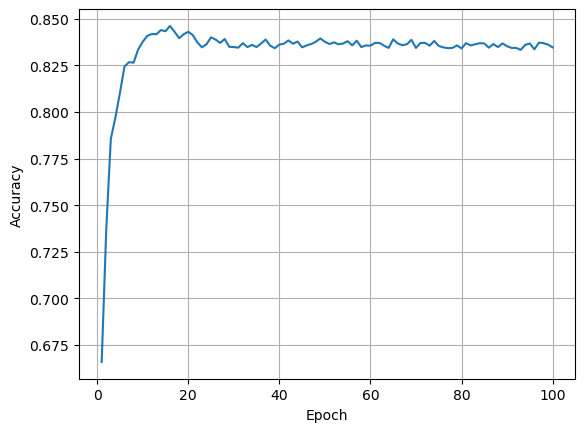

In [14]:
if __name__ == '__main__':
    # 创建 RNN 分类器实例
    classifier = RNNClassifier(N_CHARS, HIDDEN_SIZE, N_COUNTRY, N_LAYER)
    # 检查是否有 GPU 可用，并将模型移动到相应的设备上
    if USE_GPU:
        classifier.to(device)
    
    # 定义损失函数和优化器
    criterion = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(classifier.parameters(), lr=0.001)

    start = time.time()  # 记录训练开始时间
    print("Training for %d epochs..." % N_EPOCHS)
    acc_list = []  # 用于存储每个轮次的准确率

    # 训练循环
    for epoch in range(1, N_EPOCHS + 1):
        # 训练模型
        trainModel()
        # 测试模型并获取准确率
        acc = testModel()
        # 记录准确率
        acc_list.append(acc)

    # 绘制准确率曲线
    epoch = np.arange(1, len(acc_list) + 1)
    acc_list = np.array(acc_list)
    plt.plot(epoch, acc_list)
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.grid()
    plt.show()

In [15]:
def predict(name):
    arr, length = name2list(name)
    inputs = torch.LongTensor([arr])
    seq_lengths = torch.LongTensor([length])
    inputs = create_tensor(inputs)
    classifier.eval()
    with torch.no_grad():
        output = classifier(inputs, seq_lengths)
        pred = output.argmax(dim=1).item()
        country = trainset.idx2country(pred)
    return country

In [30]:
predict("Saliba")

'Arabic'